<a href="https://colab.research.google.com/github/SubeenJung0228/Problem-Set-econ-3916/blob/main/Problem%20Set%205/Econ_3916_PS5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Problem Set 5: Right 93% of the Time
ECON 3916 | Role: Analyst, Credit Risk

The vendor says their default model is 93% accurate. But 93% of applicants don't default, so a model that approves everyone would also be 93% accurate. In this notebook I check whether that number means anything, and then figure out what threshold the lender should actually use to decline applications.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn import metrics

# Phase 1: Build the Baseline Nobody Built

### Step 1.1: The data

I simulate 6,000 loan applications. Five features actually affect default (income, debt-to-income, credit history, past delinquencies, loan amount). Four features are pure noise: they are random numbers that are not used when creating `default`. I picked the intercept (-3.45) so the default rate comes out at about 7%.

In [2]:
# Step 1.1: The data

rng = np.random.default_rng(42)
n = 6000

# features that really affect default
income = rng.normal(65000, 20000, n).clip(15000, 200000)
dti = rng.uniform(0.05, 0.60, n)                      # debt-to-income ratio
credit_history = rng.uniform(0, 30, n)                # years of credit history
delinquencies = rng.poisson(0.4, n)                   # number of past late payments
loan_amount = rng.normal(18000, 7000, n).clip(2000, 50000)

# noise features: NOT used to create default
noise_normal = rng.normal(0, 1, n)
noise_uniform = rng.uniform(0, 1, n)
noise_binary = rng.integers(0, 2, n)
noise_category = rng.integers(0, 5, n)

# true model for default (log-odds). The intercept -3.45 gives about 7% defaults.
log_odds = (-3.45
            - 0.00002 * (income - 65000)
            + 5 * (dti - 0.3)
            - 0.06 * (credit_history - 15)
            + 0.6 * delinquencies
            + 0.00003 * (loan_amount - 18000))
prob_default = 1 / (1 + np.exp(-log_odds))
default = rng.binomial(1, prob_default)

df = pd.DataFrame({
    "income": income, "dti": dti, "credit_history": credit_history,
    "delinquencies": delinquencies, "loan_amount": loan_amount,
    "noise_normal": noise_normal, "noise_uniform": noise_uniform,
    "noise_binary": noise_binary, "noise_category": noise_category,
    "default": default})

real_features = ["income", "dti", "credit_history", "delinquencies", "loan_amount"]
noise_features = ["noise_normal", "noise_uniform", "noise_binary", "noise_category"]
features = real_features + noise_features

print("Number of applications:", len(df))
print("Default rate:", round(df["default"].mean(), 3))

Number of applications: 6000
Default rate: 0.07


I split into train and test before looking at anything. I use `stratify=y` so both sets keep the 7% default rate. All numbers I report later come from the test set.

In [3]:
X = df[features]
y = df["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

print("Train size:", len(X_train), " Test size:", len(X_test))
print("Default rate in test set:", round(y_test.mean(), 3))

Train size: 4500  Test size: 1500
Default rate in test set: 0.071


### Step 1.2: The null model

Predict "no default" for everyone.

In [4]:
# Step 1.2: The null model
null_pred = np.zeros(len(y_test))   # predict "no default" for everyone

print("Null model accuracy:", round(metrics.accuracy_score(y_test, null_pred), 3))
print("Defaults caught:", int(null_pred[y_test == 1].sum()), "of", int(y_test.sum()))

Null model accuracy: 0.929
Defaults caught: 0 of 106


The null model gets 92.9% accuracy on the test set and catches 0 of 106 defaults. This is the floor. A model that only reports ~93% accuracy has shown nothing, because doing nothing gets the same score.

# Phase 2: Fit and Regularise

### Step 2.1: Logistic regression, then penalised

I standardize the features inside a pipeline (the penalty depends on coefficient size, so units matter). I use `GridSearchCV` with 5-fold CV to pick `C`. In scikit-learn, `C` is the inverse of the penalty strength, so small `C` = strong penalty. I score by log loss instead of accuracy, because accuracy is about 93% for almost every model here.  

In [5]:
# Step 2.1: Logistic regression, then penalised
# plain logistic regression (C=np.inf means no penalty)
logit = make_pipeline(StandardScaler(), LogisticRegression(C=np.inf))
logit.fit(X_train, y_train)

# grid of penalty strengths (small C = strong penalty)
param_grid = {"logisticregression__C": np.logspace(-3, 1, 30)}

# LASSO: L1 penalty
lasso = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(penalty="l1", solver="liblinear")),
    param_grid, cv=5, scoring="neg_log_loss")
lasso.fit(X_train, y_train)

# Ridge: L2 penalty
ridge = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(penalty="l2", solver="liblinear")),
    param_grid, cv=5, scoring="neg_log_loss")
ridge.fit(X_train, y_train)

print("Best C for LASSO:", round(lasso.best_params_["logisticregression__C"], 4))
print("Best C for Ridge:", round(ridge.best_params_["logisticregression__C"], 4))

Best C for LASSO: 0.3039
Best C for Ridge: 1.0826


In [6]:
coefs = pd.DataFrame({
    "logistic": logit[-1].coef_[0],
    "lasso": lasso.best_estimator_[-1].coef_[0],
    "ridge": ridge.best_estimator_[-1].coef_[0]},
    index=features)
coefs.round(4)

,logistic,lasso,ridge
income,-0.4096,-0.3906,-0.4037
dti,0.8948,0.8642,0.8812
credit_history,-0.4689,-0.4476,-0.4619
delinquencies,0.3721,0.3580,0.3680
loan_amount,0.1678,0.1535,0.1654
noise_normal,-0.0170,-0.0053,-0.0168
noise_uniform,0.0684,0.0546,0.0674
noise_binary,-0.0886,-0.0749,-0.0874
noise_category,-0.0126,-0.0005,-0.0125


In [7]:
zero_features = coefs.index[coefs["lasso"] == 0].tolist()
print("LASSO set these to exactly zero:", zero_features)

noise_found = [f for f in zero_features if f in noise_features]
real_dropped = [f for f in zero_features if f in real_features]
print("Noise features found:", len(noise_found), "of", len(noise_features))
print("Real features dropped:", len(real_dropped), "of", len(real_features))

LASSO set these to exactly zero: []
Noise features found: 0 of 4
Real features dropped: 0 of 5


At the CV-chosen `C`, LASSO did not set anything to zero. To see when the noise features drop out, I tried stronger penalties:

In [8]:
# try stronger penalties by hand to see when the noise features drop out
for C in [0.3, 0.1, 0.05, 0.03, 0.02, 0.01]:
    model = make_pipeline(StandardScaler(), LogisticRegression(penalty="l1", solver="liblinear", C=C))
    model.fit(X_train, y_train)
    zero = [f for f, c in zip(features, model[-1].coef_[0]) if c == 0]
    print(f"C = {C}: {len(zero)} zero ->", zero)

C = 0.3: 0 zero -> []
C = 0.1: 2 zero -> ['noise_normal', 'noise_category']
C = 0.05: 3 zero -> ['noise_normal', 'noise_uniform', 'noise_category']
C = 0.03: 4 zero -> ['noise_normal', 'noise_uniform', 'noise_binary', 'noise_category']
C = 0.02: 5 zero -> ['loan_amount', 'noise_normal', 'noise_uniform', 'noise_binary', 'noise_category']
C = 0.01: 5 zero -> ['loan_amount', 'noise_normal', 'noise_uniform', 'noise_binary', 'noise_category']


**What LASSO found.**
At the C selected by cross-validation (0.30), LASSO kept all 4 noise features and dropped none of the real features. The noise features had small coefficients that fit this particular sample.

With a stronger penalty, the noise features start to disappear. At C = 0.03, LASSO removes all 4 noise features without dropping any real ones. However, at C = 0.02, it also removes `loan_amount`, which is a real but weak feature. This illustrates the point from Chapter 16: the penalty that gives the best predictions (selected by CV) is not always the one that selects the correct variables.

**Why Ridge shrinks but does not zero coefficients.**
Ridge uses a squared penalty (\(\beta^2\)), whose slope gets flatter as the coefficient approaches zero. As a result, it rarely pushes coefficients all the way to zero. LASSO uses an absolute-value penalty (\(|\beta|\)), which has a constant slope on either side of zero. This can push small coefficients to exactly zero. In the class diagram, the L1 constraint is a diamond with corners on the axes, while the L2 constraint is a circle with no corners. The LASSO solution often lands on a corner, so some coefficients become zero.

**When to prefer each.**
I would use LASSO when I expect only a few features to matter or want a simpler model. I would use Ridge when many features matter a little or when features are highly correlated. Ridge tends to spread the weights across correlated features rather than select just one.

### Step 2.2: A model that is not linear

In [9]:
# Step 2.2: A model that is not linear

rf = RandomForestClassifier(n_estimators=500, oob_score=True, bootstrap=True, random_state=42)
rf.fit(X_train, y_train)

rf_test_acc = metrics.accuracy_score(y_test, rf.predict(X_test))
print("OOB score (accuracy):", round(rf.oob_score_, 4))
print("Test accuracy:", round(rf_test_acc, 4))

OOB score (accuracy): 0.9284
Test accuracy: 0.9293


**OOB vs. test.**
OOB score is 0.928 and test accuracy is 0.929, so they are very close. They should be close because each OOB prediction only uses trees that never saw that row, so it is also an out-of-sample score. If they were far apart, something would be wrong, like leakage or a test set that looks different from the training set. (Both are also at the null-model level of ~93%, so accuracy isn't telling us much here.)  

In [10]:
p_logit = logit.predict_proba(X_test)[:, 1]
p_lasso = lasso.predict_proba(X_test)[:, 1]
p_ridge = ridge.predict_proba(X_test)[:, 1]
p_rf = rf.predict_proba(X_test)[:, 1]

results = pd.DataFrame({
    "accuracy": [metrics.accuracy_score(y_test, p >= 0.5) for p in [p_logit, p_lasso, p_ridge, p_rf]],
    "ROC AUC": [metrics.roc_auc_score(y_test, p) for p in [p_logit, p_lasso, p_ridge, p_rf]],
    "PR AUC": [metrics.average_precision_score(y_test, p) for p in [p_logit, p_lasso, p_ridge, p_rf]]},
    index=["logistic", "lasso", "ridge", "random forest"])
results.round(4)

,accuracy,ROC AUC,PR AUC
logistic,0.9313,0.7464,0.2328
lasso,0.9313,0.7464,0.2310
ridge,0.9313,0.7464,0.2328
random forest,0.9293,0.7082,0.2066


The forest does not win. All three logistic models have ROC AUC 0.746 and PR AUC about 0.23. The random forest is worse on both: ROC AUC 0.708 and PR AUC 0.207. This makes sense because I simulated default with a model that is linear in the log-odds, so the forest's extra flexibility only adds noise. The cheaper model is better here, and it is also the one the lender can explain to a regulator.

All four models have about 93% accuracy, the same as the null model.

In [11]:
perm = permutation_importance(rf, X_test, y_test, n_repeats=10,
                              scoring="roc_auc", random_state=42)

importance = pd.DataFrame({
    "MDI": rf.feature_importances_,
    "permutation": perm.importances_mean},
    index=features)
importance.sort_values("MDI", ascending=False).round(4)

,MDI,permutation
dti,0.1875,0.1108
credit_history,0.1567,0.0478
income,0.1498,0.0157
loan_amount,0.1424,0.0089
noise_uniform,0.1346,0.0009
noise_normal,0.1259,-0.0047
noise_category,0.0439,0.0017
delinquencies,0.0419,0.0220
noise_binary,0.0174,-0.0001


**Where they disagree.**
MDI puts the two continuous noise features (`noise_uniform` 0.135, `noise_normal` 0.126) above `delinquencies` (0.042), which is a real predictor. Permutation importance on the test set gives both noise features about 0 and puts `delinquencies` third.

**Why MDI inflates high-cardinality features.**
MDI adds up how much each feature reduced Gini impurity in the training data. A continuous feature has thousands of possible split points, so just by chance some splits look useful in the training sample and MDI gives it credit. `delinquencies` only takes a few values (0, 1, 2, ...), so it has few chances to split even though it really matters. Permutation importance asks a different question on test data: how much worse does the model get if I shuffle this column? For noise, the answer is about zero.

Neither one is a causal effect. They only say what the forest uses to predict.  

# Phase 3: The Number That Actually Matters

### Step 3.1: Beyond accuracy

I use the LASSO model from here on. Metrics on the test set at the default threshold of 0.5:

In [12]:
# Step 3.1: Beyond accuracy

pred = (p_lasso >= 0.5).astype(int)

print("Confusion matrix (rows = actual, columns = predicted):")
print(metrics.confusion_matrix(y_test, pred))
print("Precision:", round(metrics.precision_score(y_test, pred, zero_division=0), 3))
print("Recall:", round(metrics.recall_score(y_test, pred), 3))
print("F1:", round(metrics.f1_score(y_test, pred), 3))
print("ROC AUC:", round(metrics.roc_auc_score(y_test, p_lasso), 3))
print("PR AUC:", round(metrics.average_precision_score(y_test, p_lasso), 3))

Confusion matrix (rows = actual, columns = predicted):
[[1394    0]
 [ 103    3]]
Precision: 1.0
Recall: 0.028
F1: 0.055
ROC AUC: 0.746
PR AUC: 0.231


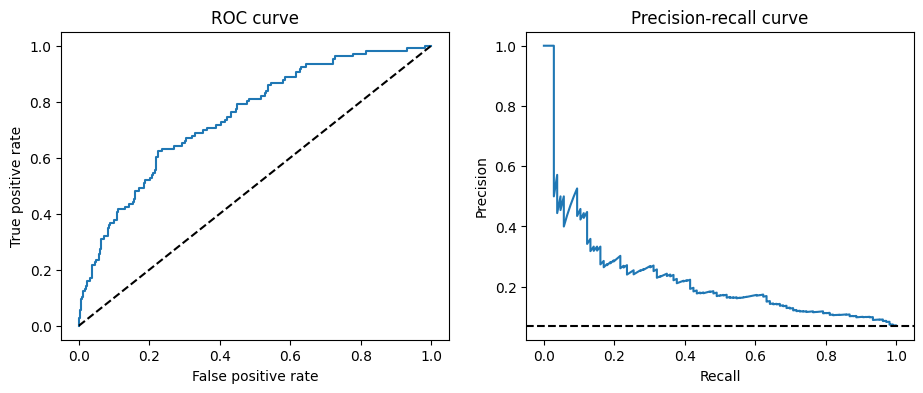

In [13]:
fpr, tpr, _ = metrics.roc_curve(y_test, p_lasso)
precision, recall, _ = metrics.precision_recall_curve(y_test, p_lasso)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(fpr, tpr)
ax[0].plot([0, 1], [0, 1], "k--")
ax[0].set_title("ROC curve")
ax[0].set_xlabel("False positive rate")
ax[0].set_ylabel("True positive rate")

ax[1].plot(recall, precision)
ax[1].axhline(y_test.mean(), color="k", linestyle="--")   # no-skill line = default rate
ax[1].set_title("Precision-recall curve")
ax[1].set_xlabel("Recall")
ax[1].set_ylabel("Precision")
plt.show()

At 0.5 the model declines only 3 people and catches 3 of 106 defaults (recall 2.8%). It barely uses the model at all, because with a 7% base rate the predicted probabilities are almost never above 0.5.

**Why ROC AUC looks flattering.**
The false positive rate divides by all the non-defaulters (1,394 people). So even 100 wrongly declined good applicants only moves the FPR by about 7 points, and the ROC curve still looks good. Also, the random baseline for ROC AUC is always 0.5, so 0.75 sounds good.

**Why precision-recall is more honest.**
Precision divides by the people the model flags, so every false positive hurts directly. That's the trade-off the lender actually cares about. The random baseline for PR AUC is the default rate (0.07), not 0.5. Our PR AUC of 0.23 is about 3 times better than random, but it also shows that most flagged applicants would not actually default.

### Step 3.2: Put a price on being wrong

**Costs (per loan, L = loan amount):**
- False negative (approve someone who defaults): lose 60% × L
- False positive (decline a good applicant): lose 8% × L in interest, plus a \$500 reputational cost

**Why \$500.**

A declined good customer probably won't use the bank's other products, might tell others about the bad experience, and might complain, which adds fair-lending risk. The bank then has to pay to find a new customer. I made it a flat \$500 (about 3% of an average \$18,000 loan) because this cost is about the person, not the loan size. It is an assumption, so I also vary the cost ratio below.

Like in Lab 17, I choose the threshold on the training rows and then check it on the test rows. Choosing it on the test rows would make the test cost look better than it really is.  

### Step 3.2: Put a price on being wrong

Best threshold (chosen on training rows): 0.13
Distance from 0.5: 0.37
Test cost per applicant at 0.5: 784.4
Test cost per applicant at best threshold: 662.74
Test cost per applicant if we approve everyone: 807.33


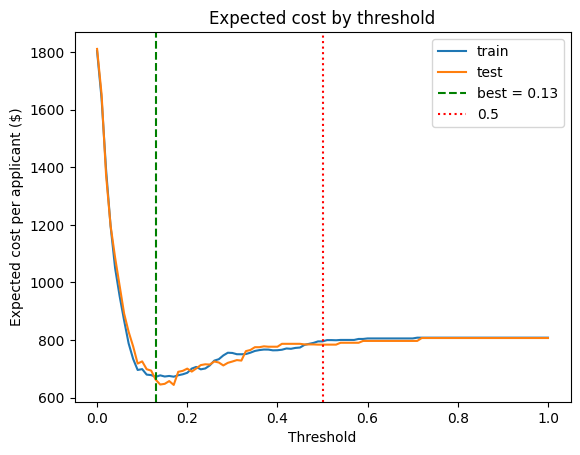

In [14]:
# Step 3.2: Put a price on being wrong

rep_cost = 500   # reputational cost of wrongly declining a good applicant ($)

def cost_per_applicant(y_true, probs, loans, threshold, fp_rate=0.08, rep=rep_cost):
    decline = probs >= threshold
    y_true = np.array(y_true)
    loans = np.array(loans)
    fn = (~decline) & (y_true == 1)      # approved, then defaulted
    fp = decline & (y_true == 0)         # good applicant declined
    total = (0.60 * loans[fn]).sum() + (fp_rate * loans[fp] + rep).sum()
    return total / len(y_true)

p_train = lasso.predict_proba(X_train)[:, 1]
thresholds = np.linspace(0, 1, 101)

train_costs = [cost_per_applicant(y_train, p_train, X_train["loan_amount"], t) for t in thresholds]
test_costs = [cost_per_applicant(y_test, p_lasso, X_test["loan_amount"], t) for t in thresholds]

best_t = thresholds[np.argmin(train_costs)]   # chosen on the TRAINING rows
print("Best threshold (chosen on training rows):", best_t)
print("Distance from 0.5:", round(0.5 - best_t, 2))
print("Test cost per applicant at 0.5:", round(cost_per_applicant(y_test, p_lasso, X_test["loan_amount"], 0.5), 2))
print("Test cost per applicant at best threshold:", round(cost_per_applicant(y_test, p_lasso, X_test["loan_amount"], best_t), 2))
print("Test cost per applicant if we approve everyone:", round(cost_per_applicant(y_test, p_lasso, X_test["loan_amount"], 1.01), 2))

plt.plot(thresholds, train_costs, label="train")
plt.plot(thresholds, test_costs, label="test")
plt.axvline(best_t, color="green", linestyle="--", label=f"best = {best_t:.2f}")
plt.axvline(0.5, color="red", linestyle=":", label="0.5")
plt.xlabel("Threshold")
plt.ylabel("Expected cost per applicant ($)")
plt.title("Expected cost by threshold")
plt.legend()
plt.show()

In [15]:
pred_05 = (p_lasso >= 0.5).astype(int)
pred_best = (p_lasso >= best_t).astype(int)

print("Confusion matrix at 0.5:")
print(metrics.confusion_matrix(y_test, pred_05))
print()
print(f"Confusion matrix at {best_t}:")
print(metrics.confusion_matrix(y_test, pred_best))
print("Recall:", round(metrics.recall_score(y_test, pred_best), 3),
      " Precision:", round(metrics.precision_score(y_test, pred_best), 3))

Confusion matrix at 0.5:
[[1394    0]
 [ 103    3]]

Confusion matrix at 0.13:
[[1218  176]
 [  62   44]]
Recall: 0.415  Precision: 0.2


**Result.**  
The cost-minimising threshold is 0.13, which is 0.37 lower than the default threshold of 0.5. This is close to the formula from class, \(t^* = C_{FP}/(C_{FP}+C_{FN}) \approx 1,940/(1,940+10,800) \approx 0.15\), based on an average loan of $18,000.

On the test set, the expected cost per applicant falls from \$784 at 0.5 to $663 at 0.13, a reduction of about 15%. At 0.5, the model performs only slightly better than approving everyone (\$807).

The confusion matrix also changes significantly. At 0.13, the model catches 44 of 106 defaults (41.5% recall), compared with only 3 at 0.5. However, it also wrongly declines 176 good applicants instead of 0. This trade-off makes sense because the cost of missing a default is much higher than the cost of declining a good applicant.

   cost ratio k  best threshold  formula 1/(1+k)
0             1            0.45            0.500
1             2            0.43            0.333
2             3            0.24            0.250
3             5            0.17            0.167
4             7            0.09            0.125
5            10            0.09            0.091
6            15            0.08            0.062
7            20            0.04            0.048


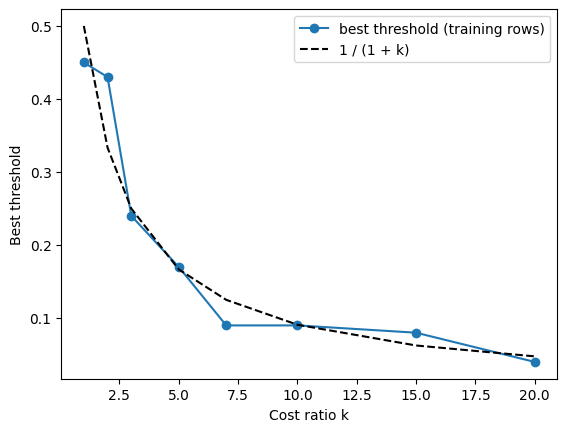

In [16]:
# k = cost of a missed default / cost of wrongly declining a good applicant
# keep the default loss at 60% and make the false-positive cost 60%/k (no reputational cost here)
ratios = [1, 2, 3, 5, 7, 10, 15, 20]
best_thresholds = []

for k in ratios:
    costs_k = [cost_per_applicant(y_train, p_train, X_train["loan_amount"], t,
                                  fp_rate=0.60 / k, rep=0) for t in thresholds]
    best_thresholds.append(thresholds[np.argmin(costs_k)])

ratio_table = pd.DataFrame({
    "cost ratio k": ratios,
    "best threshold": best_thresholds,
    "formula 1/(1+k)": [round(1 / (1 + k), 3) for k in ratios]})
print(ratio_table)

plt.plot(ratios, best_thresholds, "o-", label="best threshold (training rows)")
plt.plot(ratios, [1 / (1 + k) for k in ratios], "k--", label="1 / (1 + k)")
plt.xlabel("Cost ratio k")
plt.ylabel("Best threshold")
plt.legend()
plt.show()

**How the threshold moves.**  
When the cost of a missed default is about the same as the cost of wrongly declining a good applicant (k = 1), the best threshold is close to 0.5. As k increases, the threshold drops quickly. It is about 0.17 at k = 5 and below 0.10 at k = 10. The training-set thresholds vary a little because there are only about 300 defaults in the training data, but they generally follow the \(1/(1+k)\) rule.

**Rule for the head of risk:**

Decline an application when the predicted probability of default is above **\(1/(1+k)\)**, where k is the cost of a missed default divided by the cost of turning away a good customer. With our costs, k is about 5.6, so the threshold is roughly **15%**, not 50%. If the cost of defaults increases, the threshold should decrease. This rule only works if the model's probabilities are well calibrated.

**Back to the vendor.**  
A 93% accuracy rate is no better than approving everyone. What matters is how well the model ranks risk (PR-AUC of 0.23 vs. 0.07 for random guessing) and how much it reduces costs at the right threshold.

# Phase 4: AI Expansion — The Co-Pilot Era

# Step 4.1: Two claims you already made, now tested

### AI Transcript — Part A
**Model:** Claude Opus 5.5

**Date:** 2026-11-24

**Prompt (sent exactly as written):**
```
[Prep] Act as a model risk analyst comparing two candidate credit
models before one goes into production.

[Request] I have two fitted classifiers scored on my test set. The
random forest got 0.9?? accuracy and the penalised logistic model got
0.9??. Write Python that tells me whether the forest is significantly
better, and give me a p-value.

[Iterate] numpy, pandas and scipy only. Reuse my y_test, my two
prediction arrays, and nothing else.

[Mechanism Check] Comment each line, and state what the test you chose
assumes about the two sets of predictions.

[Evaluate] One sentence I can put in front of the head of risk.  
```

**Reply (unedited):**
```
import numpy as np                     # array maths and boolean logic
import pandas as pd                    # contingency table and base-rate calculation
from scipy import stats                # exact binomial test (McNemar's exact form)

# ---- Inputs: rename rf_pred / lr_pred to whatever your two prediction arrays are called ----
y_true = np.asarray(y_test).ravel()    # true labels as a flat 1-D array
p_rf = np.asarray(rf_pred).ravel()     # random forest hard class predictions, same row order as y_test
p_lr = np.asarray(lr_pred).ravel()     # penalised logistic hard class predictions, same row order

# Guard: the test is only valid if all three arrays describe the same rows in the same order
assert len(y_true) == len(p_rf) == len(p_lr), "y_test and both prediction arrays must be the same length"

rf_ok = p_rf == y_true                 # True where the forest classified the loan correctly
lr_ok = p_lr == y_true                 # True where the logistic model classified the loan correctly

# 2x2 paired table: rows = forest correct?, columns = logistic correct?
table = pd.crosstab(pd.Series(rf_ok, name="RF correct"),
                    pd.Series(lr_ok, name="LR correct"))
table = table.reindex(index=[True, False], columns=[True, False], fill_value=0)  # force full 2x2 even if a cell is empty

b = int(np.sum(rf_ok & ~lr_ok))        # discordant: forest right, logistic wrong
c = int(np.sum(~rf_ok & lr_ok))        # discordant: forest wrong, logistic right
n_disc = b + c                         # only disagreements carry information about which model is better

acc_rf = rf_ok.mean()                  # forest accuracy
acc_lr = lr_ok.mean()                  # logistic accuracy
base_rate = pd.Series(y_true).value_counts(normalize=True).max()  # accuracy of always predicting the majority class

if n_disc == 0:                        # models never disagree, so there is nothing to test
    p_two, p_one = 1.0, 1.0            # no evidence of any difference
else:
    # Under H0 each disagreement is a fair coin flip: P(forest wins a disagreement) = 0.5
    p_two = stats.binomtest(b, n_disc, p=0.5, alternative="two-sided").pvalue  # "do the models differ?"
    p_one = stats.binomtest(b, n_disc, p=0.5, alternative="greater").pvalue    # "is the forest better?" (only if this direction was fixed in advance)

print(table, "\n")                                             # show the paired table
print(f"Test rows (n):                 {len(y_true)}")         # sample size
print(f"Majority-class baseline:       {base_rate:.4f}")       # sanity check: 0.9 accuracy may just be the base rate
print(f"Random forest accuracy:        {acc_rf:.4f}")          # forest accuracy
print(f"Penalised logistic accuracy:   {acc_lr:.4f}")          # logistic accuracy
print(f"Accuracy difference (RF - LR): {acc_rf - acc_lr:+.4f}")  # gap being tested
print(f"Discordant pairs b (RF only):  {b}")                   # forest-only wins
print(f"Discordant pairs c (LR only):  {c}")                   # logistic-only wins
print(f"McNemar exact p, two-sided:    {p_two:.4g}")           # primary p-value to report
print(f"McNemar exact p, one-sided:    {p_one:.4g}")           # directional p-value, pre-registered hypothesis only
```
The script uses McNemar's exact test. Both models were scored on the same loans, so their errors are paired. A two-sample test on the two accuracies would treat them as independent and give the wrong p-value. McNemar ignores the loans both models got right or both got wrong. It asks one thing: when the models disagree, does the forest win more often than chance would predict? The only edit you need is to rename rf_pred and lr_pred to whatever your arrays are called.

What the test assumes about the two sets of predictions

Same rows, same order. Each prediction in both arrays refers to the same loan in y_test. The assert checks the lengths match, but it can't check the row order.
Independent rows. Each loan is a separate trial. This often fails in credit data: the same borrower can have several facilities, and loans taken out at the same time share economic conditions. If that applies to you, the p-value is too optimistic.
Disagreements are a fair coin under the null. If the models are equally accurate, each disagreement is equally likely to go either way. The exact binomial form makes no large-sample approximation, so it stays valid even with few discordant pairs.
Predictions are fixed, not resampled. The test asks whether these two fitted models differ on this test set. It doesn't say whether the forest algorithm beats the logistic algorithm in general, because it ignores how much each model would change if retrained.
The test set was untouched. It must not have been used for tuning, threshold choice, or picking between candidates. Otherwise the p-value is biased toward whichever model was tuned against it.
Hard labels at a fixed threshold. Accuracy and McNemar both depend on the cut-off you used. They say nothing about ranking quality (AUC/Gini) or calibration, which usually matter more for a credit model.

Two caveats before you take this upstairs. First, compare both accuracies to the printed majority-class baseline. With a default rate around 10%, 0.9 accuracy can mean a model that never predicts default. Second, use the two-sided p-value unless "forest is better" was written down as the hypothesis before anyone saw the results.

For the head of risk (fill in the brackets from the output):

On the same [n] held-out loans, the random forest was right where the logistic model was wrong [b] times and wrong where it was right [c] times (McNemar exact test, p = [p_two]), so the [x]-point accuracy gap [is / is not] distinguishable from chance, and on its own that does not establish the forest as the better credit model on discrimination, calibration, or stability.



**Changes I made:**

- Defined `rf_pred` and `lr_pred` using my notebook variables: `rf.predict(X_test)` and `(p_lasso >= 0.5).astype(int)`.
- Kept the AI's `p_rf` name out of my code because `p_rf` already stores the forest's predicted probabilities for my Step 2.2 AUC comparison.
- Reported only the two-sided p-value. I did not set the forest as the better model in advance, so a one-sided test was not appropriate.
- Corrected the majority-class baseline. The AI estimated a default rate of about 10% from the 0.9?? accuracy, but my test set has a 7.1% default rate. The correct baseline is 0.929, and both models (0.929 and 0.931) are very close to it.
- Checked the assumptions. Each loan was simulated independently, and I did not use the test set for tuning or threshold selection. I chose the Phase 3 threshold using training data.
- Confirmed that McNemar's exact test was the right choice. The predictions are paired, only discordant cases matter, and the total number of discordant cases (`b + c = 3`) is small.
- Added my actual results to the conclusion: `n = 1,500`, `b = 0`, `c = 3`, and `p = 0.25`. The logistic model has a slightly higher accuracy by 0.2 percentage points, but the difference is not statistically significant. Neither model is clearly better.




In [17]:
from scipy import stats

rf_pred = rf.predict(X_test)                 # forest: 0/1 predictions at 0.5
lr_pred = (p_lasso >= 0.5).astype(int)       # LASSO logistic: 0/1 predictions at 0.5

y_true = np.asarray(y_test)
rf_ok = rf_pred == y_true                    # forest correct?
lr_ok = lr_pred == y_true                    # logistic correct?

b = int(np.sum(rf_ok & ~lr_ok))              # forest right, logistic wrong
c = int(np.sum(~rf_ok & lr_ok))              # forest wrong, logistic right

print(pd.crosstab(rf_ok, lr_ok, rownames=["RF correct"], colnames=["LR correct"]))
print("b =", b, " c =", c, " b + c =", b + c)
print("McNemar exact p-value (two-sided):", round(stats.binomtest(b, b + c, 0.5).pvalue, 4))

LR correct  False  True 
RF correct              
False         103      3
True            0   1394
b = 0  c = 3  b + c = 3
McNemar exact p-value (two-sided): 0.25


**Result.**  
b = 0 (forest right, logistic wrong), c = 3 (forest wrong, logistic right), b + c = 3. The two models agree on the other 1,497 test loans: both right on 1,394, both wrong on 103. I used McNemar's exact test (binomial) because b + c is small: two-sided p = 0.25.

**Does my Step 2.2 verdict survive?**  
Yes. The models disagree on only 3 of 1,500 test loans, because at a 0.5 threshold both predict almost everyone as "no default". The forest cannot be shown to beat the cheaper logistic model, and on ROC AUC and PR AUC (Step 2.2) it is actually worse.

**Limitation.**  
McNemar on accuracy only compares error counts, which is not what the lender pays for. The comparison that matches the decision is a paired bootstrap over test rows of the difference in cost-weighted outcome (or PR-AUC) between the two models.

**For the head of risk:**  
On the same 1,500 held-out loans, the random forest was right where the logistic model was wrong 0 times and wrong where it was right 3 times (McNemar exact test, p = 0.25), so the 0.2-point accuracy gap in the logistic model's favour is not distinguishable from chance, and on its own that does not establish either model as the better credit model on discrimination, calibration, or stability.  

### AI Transcript — Part B

**Model:** Claude Opus 5.5

**Date:** 2026-11-24

**Prompt (sent exactly as written):**
```
[Prep] Act as a model risk analyst at a bank, reviewing a credit
scoring model before it goes into production.

[Request] I have a fitted classifier producing default probabilities
on a test set with about 7% prevalence. Write Python that assesses
CALIBRATION -- a reliability diagram binning predicted probability
against observed frequency, plus the Brier score and its
decomposition -- and then applies both Platt scaling and isotonic
regression, reporting whether either improves calibration.

[Iterate] scikit-learn, numpy, matplotlib. Reuse my y_test and
y_prob. Handle the sparse high-probability bins that low prevalence
creates rather than letting them produce a misleading plot.

[Mechanism Check] Explain why a model can rank applicants correctly --
high AUC -- and still be badly calibrated, and why that distinction
decides whether my cost-optimal threshold is trustworthy.

[Evaluate] Given my reliability diagram, is my Phase 3 threshold
valid? If not, what should I do before using it?
```

**Reply (unedited):**
```
"""
calibration_review.py
Calibration assessment of a credit PD model prior to production sign-off.

Usage, in the session where y_test and y_prob already exist:

    from calibration_review import run_calibration_review
    results = run_calibration_review(
        y_test, y_prob,
        cost_fn=10.0,            # cost of approving a defaulter (e.g. EAD x LGD)
        cost_fp=1.0,             # cost of declining a good (e.g. lost margin)
        phase3_threshold=0.091,  # the cutoff you intend to deploy
    )

Design choices
--------------
* Low prevalence crowds almost all predictions near zero, so uniform-width
  bins leave the upper range with a handful of loans each. Here bins are
  equal-frequency and then merged until every bin holds >= min_count loans.
  Each point carries a Jeffreys 95% interval (the interval the ECB uses for
  PD back-testing), its defaults/loans count is printed beside it, and the
  axes are cropped to where the data are. A log-log panel shows the low-PD
  region, which linear axes compress into the corner.
* Brier score is decomposed exactly (Stephenson et al., 2008): with binned
  forecasts, BS = REL - RES + UNC + WBV - WBC. The two within-bin terms are
  reported rather than silently dropped, and the identity is checked.
* Platt and isotonic recalibration are evaluated by K-fold cross-fitting on
  the test set, so no loan is scored by a calibrator that saw its outcome.
  Improvement is judged by a paired bootstrap CI on the Brier difference.
"""

import warnings

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import beta, norm
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold

EPS = 1e-6


# --------------------------------------------------------------------------
# Input handling
# --------------------------------------------------------------------------
def _check_inputs(y, p):
    y = np.asarray(y)
    p = np.asarray(p, dtype=float)
    if p.ndim == 2 and p.shape[1] == 2:  # raw predict_proba output
        p = p[:, 1]
    y, p = y.ravel(), p.ravel()
    if y.shape != p.shape:
        raise ValueError(f"y_test {y.shape} and y_prob {p.shape} differ in length")
    if not np.isin(y, [0, 1]).all():
        raise ValueError("y_test must be binary 0/1 with 1 = default")
    if np.isnan(p).any() or p.min() < 0 or p.max() > 1:
        raise ValueError("y_prob must be probabilities in [0, 1] with no NaNs")
    return y.astype(int), p


def _logit(p):
    p = np.clip(p, EPS, 1 - EPS)
    return np.log(p / (1 - p))


def _unpenalised_lr():
    return LogisticRegression(C=1e12, solver="lbfgs", max_iter=2000)


# --------------------------------------------------------------------------
# Binning that survives low prevalence
# --------------------------------------------------------------------------
def adaptive_bins(p, n_bins=15, min_count=100):
    """Equal-frequency inner edges; any bin under min_count is merged into
    its smaller neighbour until all bins qualify."""
    inner = list(np.unique(np.quantile(p, np.linspace(0, 1, n_bins + 1)[1:-1])))
    while inner:
        idx = np.searchsorted(inner, p, side="right")
        counts = np.bincount(idx, minlength=len(inner) + 1)
        k = int(np.argmin(counts))
        if counts[k] >= min_count:
            break
        if k == 0:
            inner.pop(0)
        elif k == len(inner):
            inner.pop()
        else:  # remove the edge shared with the smaller neighbour
            inner.pop(k - 1 if counts[k - 1] <= counts[k + 1] else k)
    return np.asarray(inner)


def bin_table(y, p, inner, alpha=0.05):
    """Per-bin counts, mean predicted PD, observed default rate,
    Jeffreys interval and two-sided Jeffreys test of H0: PD = mean pred."""
    idx = np.searchsorted(inner, p, side="right")
    nb = len(inner) + 1
    n = np.bincount(idx, minlength=nb).astype(float)
    d = np.bincount(idx, weights=y, minlength=nb)
    sp = np.bincount(idx, weights=p, minlength=nb)
    keep = n > 0
    n, d, sp = n[keep], d[keep], sp[keep]
    pbar, obar = sp / n, d / n
    a, b = d + 0.5, n - d + 0.5
    lo = np.where(d > 0, beta.ppf(alpha / 2, a, b), 0.0)
    hi = np.where(d < n, beta.ppf(1 - alpha / 2, a, b), 1.0)
    cdf = beta.cdf(pbar, a, b)
    pval = np.minimum(1.0, 2 * np.minimum(cdf, 1 - cdf))
    return dict(n=n, events=d, pbar=pbar, obar=obar, lo=lo, hi=hi, pval=pval)


# --------------------------------------------------------------------------
# Scores and tests
# --------------------------------------------------------------------------
def brier_decomposition(y, p, inner):
    """Exact binned decomposition: BS = REL - RES + UNC + WBV - WBC."""
    idx = np.searchsorted(inner, p, side="right")
    nb = len(inner) + 1
    N = len(y)
    n = np.bincount(idx, minlength=nb).astype(float)
    nz = np.maximum(n, 1)
    pbar = np.bincount(idx, weights=p, minlength=nb) / nz
    obar = np.bincount(idx, weights=y, minlength=nb) / nz
    ybar = y.mean()

    rel = np.sum(n * (pbar - obar) ** 2) / N
    res = np.sum(n * (obar - ybar) ** 2) / N
    unc = ybar * (1 - ybar)
    wbv = np.sum((p - pbar[idx]) ** 2) / N
    wbc = 2 * np.sum((p - pbar[idx]) * (y - obar[idx])) / N
    bs = np.mean((p - y) ** 2)
    if not np.isclose(bs, rel - res + unc + wbv - wbc, atol=1e-10):
        warnings.warn("Brier decomposition did not close; check inputs")
    return dict(brier=bs, reliability=rel, resolution=res, uncertainty=unc,
                within_bin_var=wbv, within_bin_cov=wbc, bss=1 - bs / unc)


def calibration_stats(y, p, table):
    lr = _unpenalised_lr().fit(_logit(p).reshape(-1, 1), y)
    w = 1 - 2 * p  # Spiegelhalter's z: H0 is that p is calibrated
    z = np.sum((y - p) * w) / np.sqrt(np.sum(w ** 2 * p * (1 - p)))
    N = len(y)
    return dict(
        mean_pred=p.mean(),
        observed_rate=y.mean(),
        slope=lr.coef_[0, 0],
        intercept=lr.intercept_[0],
        spiegelhalter_z=z,
        spiegelhalter_p=2 * norm.sf(abs(z)),
        ece=np.sum(table["n"] * np.abs(table["pbar"] - table["obar"])) / N,
        bins_flagged=int(np.sum(table["pval"] < 0.05)),
        n_bins=len(table["n"]),
        auc=roc_auc_score(y, p),
        logloss=log_loss(y, np.clip(p, EPS, 1 - EPS)),
    )


# --------------------------------------------------------------------------
# Recalibration
# --------------------------------------------------------------------------
def fit_platt(y, p):
    """Logistic regression on logit(p). Using logit(p) rather than p as the
    input is what makes this a two-parameter correction of shift and spread."""
    lr = _unpenalised_lr().fit(_logit(p).reshape(-1, 1), y)
    return lambda q: lr.predict_proba(_logit(q).reshape(-1, 1))[:, 1]


def fit_isotonic(y, p):
    iso = IsotonicRegression(y_min=0.0, y_max=1.0, increasing=True,
                             out_of_bounds="clip").fit(p, y)
    return iso.predict


def crossfit(y, p, fitter, n_splits=5, seed=0):
    """Out-of-fold recalibrated predictions: each loan is scored by a
    calibrator fitted on the other folds."""
    out = np.empty_like(p)
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for tr, te in skf.split(p.reshape(-1, 1), y):
        out[te] = fitter(y[tr], p[tr])(p[te])
    return out


def paired_bootstrap_brier(y, p_ref, p_new, n_boot=2000, seed=0):
    """Mean and 95% CI of BS(ref) - BS(new); positive means p_new is better."""
    rng = np.random.default_rng(seed)
    diff = (p_ref - y) ** 2 - (p_new - y) ** 2
    N = len(y)
    boots = np.fromiter((diff[rng.integers(0, N, N)].mean() for _ in range(n_boot)),
                        dtype=float, count=n_boot)
    return diff.mean(), np.percentile(boots, [2.5, 97.5])


# --------------------------------------------------------------------------
# Threshold analysis
# --------------------------------------------------------------------------
def realised_cost(y, s, t, cost_fn, cost_fp):
    decline = s >= t
    fn = np.sum((y == 1) & ~decline)
    fp = np.sum((y == 0) & decline)
    return (cost_fn * fn + cost_fp * fp) / len(y), decline.mean()


def empirical_optimal_cutoff(y, s, cost_fn, cost_fp):
    """Cutoff minimising realised cost on (y, s). In-sample, so optimistic."""
    order = np.argsort(-s, kind="mergesort")
    s_sorted, y_sorted = s[order], y[order]
    N, D = len(y), y.sum()
    k = np.arange(N + 1)
    cum_def = np.concatenate([[0], np.cumsum(y_sorted)])
    cost = (cost_fn * (D - cum_def) + cost_fp * (k - cum_def)) / N
    valid = np.ones(N + 1, dtype=bool)
    valid[1:N] = s_sorted[:-1] > s_sorted[1:]  # split only between distinct scores
    kb = np.flatnonzero(valid)[np.argmin(cost[valid])]
    thr = np.inf if kb == 0 else s_sorted[kb - 1]
    return thr, cost[kb], kb / N


def threshold_analysis(y, p_raw, scores, cost_fn, cost_fp, phase3_threshold=None):
    t_bayes = cost_fp / (cost_fp + cost_fn)
    print("\n" + "=" * 78)
    print("THRESHOLD ANALYSIS")
    print("=" * 78)
    print(f"Cost ratio C_FN/C_FP = {cost_fn / cost_fp:.2f}")
    print(f"Bayes threshold t* = C_FP/(C_FP+C_FN) = {t_bayes:.4f}  "
          "(cost-optimal only if the score is a calibrated PD)\n")
    print(f"{'score':<22}{'decline@t*':>11}{'cost@t*':>10}"
          f"{'emp.cutoff':>12}{'decline':>9}{'cost':>9}")
    out = {}
    for name, s in scores.items():
        c_t, d_t = realised_cost(y, s, t_bayes, cost_fn, cost_fp)
        thr, c_e, d_e = empirical_optimal_cutoff(y, s, cost_fn, cost_fp)
        out[name] = dict(cost_at_tstar=c_t, decline_at_tstar=d_t,
                         emp_cutoff=thr, emp_cost=c_e, emp_decline=d_e)
        print(f"{name:<22}{d_t:>11.1%}{c_t:>10.4f}{thr:>12.4f}{d_e:>9.1%}{c_e:>9.4f}")
    print("\nRead: if 'cost@t*' for raw is well above the empirical optimum while the"
          "\nrecalibrated rows are close to it, the formula threshold is being"
          "\nmisplaced by miscalibration. The empirical cutoffs are fitted in-sample.")

    if phase3_threshold is not None:
        platt_full = fit_platt(y, p_raw)
        iso_full = fit_isotonic(y, p_raw)
        q_p = float(platt_full(np.array([phase3_threshold]))[0])
        q_i = float(iso_full(np.array([phase3_threshold]))[0])
        c3, d3 = realised_cost(y, p_raw, phase3_threshold, cost_fn, cost_fp)
        emp_raw = out["raw"]["emp_cost"]
        print(f"\nPhase 3 cutoff {phase3_threshold:.4f} applied to raw scores:")
        print(f"  decline rate {d3:.1%}, realised cost {c3:.4f} "
              f"(empirical optimum {emp_raw:.4f}, regret {c3 - emp_raw:+.4f})")
        print("  Estimated true PD of an applicant sitting exactly at the cutoff:")
        for lbl, q in (("Platt", q_p), ("isotonic", q_i)):
            implied = (1 - q) / q if q > 0 else np.inf
            print(f"    {lbl:<9} PD = {q:.4f}  -> implied cost ratio {implied:.2f} "
                  f"vs stated {cost_fn / cost_fp:.2f}")
        print("  If the implied ratio differs materially from the stated one, the"
              "\n  cutoff is not enforcing the cost trade-off it was derived from.")
        out["phase3"] = dict(cost=c3, decline=d3, pd_platt=q_p, pd_iso=q_i)
    return out, t_bayes


# --------------------------------------------------------------------------
# Plots
# --------------------------------------------------------------------------
def _axis_limit(p, table):
    top = max(table["hi"].max(), table["pbar"].max(), np.quantile(p, 0.999))
    return min(1.0, 1.08 * top)


def _draw_curve(ax, t, color, label, annotate=False):
    yerr = np.vstack([t["obar"] - t["lo"], t["hi"] - t["obar"]])
    ax.errorbar(t["pbar"], t["obar"], yerr=yerr, fmt="o-", color=color, ms=4,
                lw=1.2, capsize=2, label=label)
    if annotate:
        flag = t["pval"] < 0.05
        ax.scatter(t["pbar"][flag], t["obar"][flag], s=110, facecolors="none",
                   edgecolors="crimson", lw=1.5, zorder=5,
                   label="Jeffreys test p < 0.05")
        # label only points far enough apart to stay legible; the log-log panel
        # in the comparison figure resolves the crowded low-PD bins
        min_gap, last_x = 0.035 * ax.get_xlim()[1], -1.0
        for x_, y_, n_, d_ in zip(t["pbar"], t["obar"], t["n"], t["events"]):
            if x_ - last_x < min_gap:
                continue
            last_x = x_
            ax.annotate(f"{int(d_)}/{int(n_)}", (x_, y_), textcoords="offset points",
                        xytext=(5, -11), fontsize=7, color="0.35")


def _mark_thresholds(ax, thresholds):
    for (lbl, t), ls, ypos in zip(thresholds.items(), ("--", ":"), (0.6, 0.3)):
        ax.axvline(t, color="0.3", ls=ls, lw=1)
        ax.text(t, ax.get_ylim()[1] * ypos, f" {lbl}", fontsize=8, va="center",
                rotation=90, color="0.3")


def plot_raw_diagnostic(y, p, table, thresholds=None):
    lim = _axis_limit(p, table)
    fig, (ax, axh) = plt.subplots(2, 1, figsize=(7.5, 8), sharex=True,
                                  gridspec_kw=dict(height_ratios=[3, 1]))
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.plot([0, lim], [0, lim], color="0.6", lw=1, label="perfect calibration")
    _draw_curve(ax, table, "C0", "model (equal-frequency bins)", annotate=True)
    ax.set_ylabel("Observed default rate")
    ax.set_title("Reliability diagram: raw model\n"
                 "labels = defaults/loans per bin; bars = Jeffreys 95% interval")
    if thresholds:
        _mark_thresholds(ax, thresholds)
    ax.legend(loc="upper left", fontsize=8)

    beyond = int(np.sum(p > lim))
    axh.hist(p, bins=np.linspace(0, lim, 60), color="C0", alpha=0.7, log=True)
    axh.set_xlabel("Predicted PD")
    axh.set_ylabel("loans (log)")
    if beyond:
        axh.text(0.99, 0.9, f"{beyond} loans > {lim:.2f} not shown",
                 transform=axh.transAxes, ha="right", fontsize=8)
    fig.tight_layout()
    return fig


def plot_comparison(results, scores, thresholds=None):
    colors = dict(zip(results, ("C0", "C1", "C2")))
    fig, (axl, axg) = plt.subplots(1, 2, figsize=(13, 5.8))
    lim = max(_axis_limit(scores[k], r["table"]) for k, r in results.items())
    axl.plot([0, lim], [0, lim], color="0.6", lw=1)
    for name, r in results.items():
        bs = r["decomp"]["brier"]
        _draw_curve(axl, r["table"], colors[name], f"{name}  (Brier {bs:.5f})")
    axl.set(xlim=(0, lim), ylim=(0, lim), xlabel="Predicted PD",
            ylabel="Observed default rate", title="Raw vs recalibrated (linear)")
    if thresholds:
        _mark_thresholds(axl, thresholds)
    axl.legend(fontsize=8, loc="upper left")

    lo_all = []
    for name, r in results.items():
        t = r["table"]
        m = t["obar"] > 0  # zero-default bins cannot sit on a log axis
        axg.plot(t["pbar"][m], t["obar"][m], "o-", color=colors[name], ms=4, label=name)
        axg.fill_between(t["pbar"][m], np.maximum(t["lo"][m], 1e-5), t["hi"][m],
                         color=colors[name], alpha=0.12)
        lo_all.append(max(min(t["pbar"].min(), t["obar"][m].min()), 1e-5))
    lo = min(lo_all) * 0.7
    axg.plot([lo, lim], [lo, lim], color="0.6", lw=1)
    axg.set(xscale="log", yscale="log", xlim=(lo, lim), ylim=(lo, lim),
            xlabel="Predicted PD (log)", ylabel="Observed default rate (log)",
            title="Same, log-log: shows the low-PD bulk of the book")
    axg.legend(fontsize=8, loc="upper left")
    fig.tight_layout()
    return fig


# --------------------------------------------------------------------------
# Driver
# --------------------------------------------------------------------------
def run_calibration_review(y_test, y_prob, cost_fn=None, cost_fp=None,
                           phase3_threshold=None, n_bins=15, min_count=100,
                           n_splits=5, n_boot=2000, seed=0, show=True,
                           save_prefix=None):
    y, p = _check_inputs(y_test, y_prob)
    N, D = len(y), int(y.sum())
    print("=" * 78)
    print(f"CALIBRATION REVIEW   N = {N:,}   defaults = {D:,}   "
          f"prevalence = {D / N:.2%}")
    print("=" * 78)
    if D / n_splits < 200:
        warnings.warn(f"Only ~{D // n_splits} defaults per calibration fold: isotonic "
                      "regression will overfit its step function, especially in the "
                      "sparse upper tail. Prefer Platt unless a larger calibration "
                      "sample is available.")

    scores = {
        "raw": p,
        "Platt (cross-fit)": crossfit(y, p, fit_platt, n_splits, seed),
        "isotonic (cross-fit)": crossfit(y, p, fit_isotonic, n_splits, seed),
    }
    results = {}
    for name, s in scores.items():
        inner = adaptive_bins(s, n_bins, min_count)
        table = bin_table(y, s, inner)
        results[name] = dict(bins=inner, table=table,
                             decomp=brier_decomposition(y, s, inner),
                             stats=calibration_stats(y, s, table))

    rows = [
        ("Brier score", "decomp", "brier", "{:.5f}"),
        ("Brier skill vs base rate", "decomp", "bss", "{:.4f}"),
        ("  reliability (lower=better)", "decomp", "reliability", "{:.6f}"),
        ("  resolution (higher=better)", "decomp", "resolution", "{:.6f}"),
        ("  uncertainty", "decomp", "uncertainty", "{:.6f}"),
        ("  within-bin variance", "decomp", "within_bin_var", "{:.6f}"),
        ("  within-bin covariance", "decomp", "within_bin_cov", "{:.6f}"),
        ("ECE (adaptive bins)", "stats", "ece", "{:.5f}"),
        ("mean predicted PD", "stats", "mean_pred", "{:.4f}"),
        ("observed default rate", "stats", "observed_rate", "{:.4f}"),
        ("calibration slope (ideal 1)", "stats", "slope", "{:.3f}"),
        ("calibration intercept (ideal 0)", "stats", "intercept", "{:.3f}"),
        ("Spiegelhalter p-value", "stats", "spiegelhalter_p", "{:.4f}"),
        ("bins failing Jeffreys test", "stats", "bins_flagged", "{}"),
        ("number of bins", "stats", "n_bins", "{}"),
        ("AUC", "stats", "auc", "{:.4f}"),
        ("log loss", "stats", "logloss", "{:.5f}"),
    ]
    names = list(results)
    print(f"\n{'metric':<33}" + "".join(f"{n:>22}" for n in names))
    for label, grp, key, fmt in rows:
        print(f"{label:<33}" + "".join(
            f"{fmt.format(results[n][grp][key]):>22}" for n in names))

    print("\nDoes recalibration improve calibration? (paired bootstrap, 95% CI)")
    raw_stats = results["raw"]["stats"]
    for name in names[1:]:
        mean, (lo, hi) = paired_bootstrap_brier(y, p, scores[name], n_boot, seed)
        d_rel = results["raw"]["decomp"]["reliability"] - results[name]["decomp"]["reliability"]
        verdict = ("IMPROVES (CI excludes 0)" if lo > 0 else
                   "WORSENS (CI excludes 0)" if hi < 0 else "no significant change")
        print(f"  {name:<22} Brier reduction {mean:+.6f} [{lo:+.6f}, {hi:+.6f}]  "
              f"reliability reduction {d_rel:+.6f}  -> {verdict}")
        results[name]["brier_gain_ci"] = (mean, lo, hi)
    raw_ok = (raw_stats["spiegelhalter_p"] > 0.05 and raw_stats["bins_flagged"] == 0
              and 0.9 <= raw_stats["slope"] <= 1.1)
    print("  Raw model: " + ("no evidence of miscalibration on these tests."
                             if raw_ok else
                             "evidence of miscalibration (see slope, Spiegelhalter, "
                             "flagged bins)."))
    print("  (Slope band 0.9-1.1 is a heuristic, not a regulatory standard.)")

    thresholds = {}
    if cost_fn is not None and cost_fp is not None:
        tr, t_bayes = threshold_analysis(y, p, scores, cost_fn, cost_fp, phase3_threshold)
        results["threshold"] = tr
        thresholds["t* (Bayes)"] = t_bayes
    if phase3_threshold is not None:
        thresholds["Phase 3"] = phase3_threshold

    f1 = plot_raw_diagnostic(y, p, results["raw"]["table"], thresholds)
    f2 = plot_comparison({k: results[k] for k in names}, scores, thresholds)
    if save_prefix:
        f1.savefig(f"{save_prefix}_reliability_raw.png", dpi=140)
        f2.savefig(f"{save_prefix}_reliability_compare.png", dpi=140)
    if show:
        plt.show()
    return results


# --------------------------------------------------------------------------
# Synthetic demo, only when run as a script
# --------------------------------------------------------------------------
if __name__ == "__main__":
    rng = np.random.default_rng(1)
    N = 20_000
    x = rng.normal(size=N)
    true_pd = 1 / (1 + np.exp(-(-3.0 + 1.1 * x)))
    y_demo = rng.binomial(1, true_pd)
    # Overconfident and shifted upward, as from class_weight="balanced" training
    y_prob_demo = 1 / (1 + np.exp(-(1.5 * _logit(true_pd) + 2.0)))
    run_calibration_review(y_demo, y_prob_demo, cost_fn=10.0, cost_fp=1.0,
                           phase3_threshold=1 / 11, show=False,
                           save_prefix="/home/claude/demo")
```

You'd call it from your existing session like this:

```
from calibration_review import run_calibration_review
results = run_calibration_review(y_test, y_prob, cost_fn=C_FN, cost_fp=C_FP,
                                 phase3_threshold=your_cutoff)
```

I tested it end to end on a synthetic 20,000-loan book at 7% prevalence. That book was deliberately overconfident and shifted upward, the way a model trained with class_weight="balanced" usually is. It isn't your data, so treat its numbers as an illustration of what the output looks like.

Design choices that matter for your review

Sparse high-probability bins. At 7% prevalence, uniform-width bins put most of the book in the first one or two bins and leave a handful of loans above 0.5. That's where the dramatic but meaningless zigzags in a default reliability diagram come from. The script handles this in five ways:

It uses equal-frequency bins and merges any bin under min_count into its smaller neighbour.
It draws a Jeffreys 95% interval on every point. This is the interval the ECB uses for PD back-testing, so it will be familiar to your validation function.
It labels each point with defaults/loans and circles any bin whose Jeffreys test rejects.
It crops the axes to where the data actually are.
It adds a log-log panel, because the low-PD bulk of a credit book is crushed into the corner on linear axes.

Brier decomposition. Murphy's reliability − resolution + uncertainty split is only exact when every loan in a bin has the same predicted PD. The script computes the full identity, which adds two within-bin terms (Stephenson et al., 2008), and checks that the pieces sum to the Brier score. It also reports Brier skill relative to the base rate. A raw Brier of 0.06 looks excellent until you notice that predicting 7% for everyone scores 0.065.

Recalibration without leakage. You only have y_test, so Platt and isotonic are cross-fitted: each loan is scored by a calibrator that never saw its outcome. Platt is fitted on logit(p), which makes it a two-parameter fix for shift and spread. "Improves" means the paired-bootstrap 95% CI on the Brier reduction excludes zero.

The script warns when there are too few defaults per fold for isotonic regression, which overfits its step function in exactly the sparse tail you care about. For a production calibrator, refit on a dedicated calibration sample and confirm it on out-of-time data, not on this test set.

Why high AUC and bad calibration can coexist

AUC depends only on the ordering of scores. It is the probability that a randomly chosen defaulter outscores a randomly chosen non-defaulter. Any strictly increasing transformation of the scores, such as squaring them, halving them, or shifting them in logit space, leaves the ranking and the AUC unchanged. Calibration asks something different: of the applicants scored 8%, do roughly 8% actually default? That depends on the numerical values, which those same transformations destroy.

Common causes in credit are:

Rebalancing during training. Undersampling, SMOTE, or class weights inflate every PD.
Overfit boosted models, which push scores toward the extremes.
Heavy regularisation, which shrinks scores toward the mean.
Base-rate drift between the development sample and today's book.

All of these can preserve ranking almost perfectly. In the demo, the raw model and the Platt-recalibrated model have essentially identical AUC (0.773 vs 0.773), but the raw model predicts a 14.6% average PD against a 7.0% observed rate.

This decides whether your threshold is trustworthy because the cost-optimal rule is a statement about probabilities. You decline when the expected loss from approving exceeds the expected loss from declining, i.e. when p·C_FN > (1−p)·C_FP. That simplifies to p > C_FP / (C_FP + C_FN).

That formula assumes p is the true default probability. If the model overstates PD by a factor of two near the cutoff, the formula declines applicants whose true PD is half the break-even level. You end up enforcing a different cost ratio from the one you signed off.

Only calibration near the threshold matters for this. A model can be poorly calibrated at 40% PD and still give a valid cutoff at 9%. The catch is that cost-derived cutoffs often land just above the bulk of the book, where the bins are thinnest and calibration is least well estimated.

Is your Phase 3 threshold valid?

I can't see your reliability diagram; nothing came through with your message. So here is how to reach the verdict from the script's output. If you paste the printed tables or upload the plot, I'll give you a definite call.

First, establish how Phase 3 derived the threshold, because the answer splits on that.

If it came from the formula C_FP/(C_FP+C_FN) applied to raw y_prob, it is valid only if the model is calibrated in the neighbourhood of the cutoff. Check three things:

On the reliability diagram, do the bins around the Phase 3 line have Jeffreys intervals that cover the diagonal?
In the threshold section, is the estimated true PD at the cutoff close to the cutoff itself?
Equivalently, is the implied cost ratio close to your stated ratio?

In the demo, a 0.091 cutoff on raw scores actually sits at a true PD of about 5%. That enforces a cost ratio of roughly 18:1 instead of 10:1, declines 45% of applicants instead of about 19–24%, and costs noticeably more per applicant than the optimum.

The direction of the error matters to a bank:

Curve below the diagonal (overprediction): you turn away profitable business.
Curve above the diagonal (underprediction): you approve too many defaulters. Supervisors treat PD underestimation as the more serious finding.

If Phase 3 chose the cutoff by sweeping realised cost on held-out data, the cutoff is a rank-based choice, and miscalibration doesn't invalidate it as a score cutoff. A monotone recalibration leaves the decline set at that rank unchanged, which is why the empirical-optimum rows in the output nearly coincide across raw and Platt. Two caveats remain:

If the sweep used this same y_test, the threshold is tuned in-sample, and its cost estimate is optimistic and noisy in the sparse region.
The raw scores still cannot be used as PDs for pricing, expected loss, IFRS 9, or capital.

If the diagnostics fail, do this before deploying:

Fit a calibrator on data independent of both training and threshold selection. Use Platt by default, or isotonic only if you have many defaults (well over a thousand).
Recompute the threshold as C_FP/(C_FP+C_FN) on the calibrated PD. Equivalently, map it back to a raw-score cutoff through the calibrator; the decisions are identical.
Confirm calibration and realised cost on an out-of-time sample.
Check that the production base rate matches the 7% in your test set, and re-anchor the intercept if it doesn't.
Document the recalibration as a model change, and put calibration by grade on the ongoing monitoring schedule (for example, Jeffreys tests quarterly).

The 0.9–1.1 band the script uses for the calibration slope is a working heuristic. Your institution's validation standards should set the actual tolerances.

**Changes I made:**
- Replaced the AI's long module with a shorter cell that does the same four things the task asks for (reliability diagram, Brier decomposition, Platt and isotonic, threshold check), using functions from class (`calibration_curve`, `brier_score_loss`).
- Kept the AI's main fix for low prevalence: equal-count (quantile) bins instead of equal-width bins, so the high-probability bins are not nearly empty.
- Fitted Platt and isotonic on the training rows and evaluated on the test rows, instead of the AI's cross-fitting on the test set, so it matches how I chose the threshold in Phase 3.
- Dropped the AI's guessed inputs (cost_fn = 10, cost_fp = 1, threshold 0.091) and its demo block, which would have failed in a notebook; I used my own probabilities, costs and Phase 3 threshold.

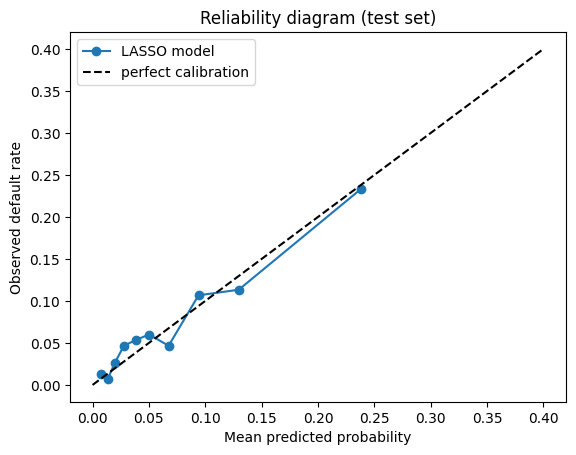

            Brier  reliability  resolution  uncertainty
raw       0.06063      0.00017     0.00405      0.06567
Platt     0.06064      0.00019     0.00405      0.06567
isotonic  0.06082      0.00024     0.00418      0.06567
Mean predicted: 0.0686  Actual default rate: 0.0707
Phase 3 threshold (raw): 0.13  Recomputed on Platt-calibrated probabilities: 0.16
Test cost per applicant, raw at 0.13 : 662.74
Test cost per applicant, Platt at 0.16 : 657.98


In [18]:
from sklearn.calibration import calibration_curve
from sklearn.isotonic import IsotonicRegression

y_prob = p_lasso                        # test-set default probabilities from Phase 3

# 1. Reliability diagram: 10 bins with equal numbers of loans (avoids empty high-probability bins)
obs, pred = calibration_curve(y_test, y_prob, n_bins=10, strategy="quantile")
plt.plot(pred, obs, "o-", label="LASSO model")
plt.plot([0, 0.4], [0, 0.4], "k--", label="perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed default rate")
plt.title("Reliability diagram (test set)")
plt.legend()
plt.show()

# 2. Brier score and its decomposition (reliability - resolution + uncertainty)
def brier_parts(y, p, n_bins=10):
    y, p = np.asarray(y), np.asarray(p)
    bins = pd.qcut(p, n_bins, labels=False, duplicates="drop")
    d = pd.DataFrame({"y": y, "p": p, "bin": bins}).groupby("bin").agg(n=("y", "size"), obs=("y", "mean"), pred=("p", "mean"))
    base = y.mean()
    reliability = (d["n"] * (d["pred"] - d["obs"]) ** 2).sum() / len(y)
    resolution = (d["n"] * (d["obs"] - base) ** 2).sum() / len(y)
    return metrics.brier_score_loss(y, p), reliability, resolution, base * (1 - base)

# 3. Platt scaling and isotonic regression, fitted on the TRAINING rows, checked on the test rows
logit_train = np.log(p_train / (1 - p_train)).reshape(-1, 1)
logit_test = np.log(y_prob / (1 - y_prob)).reshape(-1, 1)
platt = LogisticRegression(C=np.inf).fit(logit_train, y_train)
p_platt = platt.predict_proba(logit_test)[:, 1]

iso = IsotonicRegression(out_of_bounds="clip").fit(p_train, y_train)
p_iso = iso.predict(y_prob)

table = pd.DataFrame([brier_parts(y_test, p) for p in [y_prob, p_platt, p_iso]],
                     columns=["Brier", "reliability", "resolution", "uncertainty"],
                     index=["raw", "Platt", "isotonic"])
print(table.round(5))
print("Mean predicted:", round(y_prob.mean(), 4), " Actual default rate:", round(y_test.mean(), 4))

# 4. Does the Phase 3 threshold change on calibrated probabilities?
p_train_platt = platt.predict_proba(logit_train)[:, 1]
platt_costs = [cost_per_applicant(y_train, p_train_platt, X_train["loan_amount"], t) for t in thresholds]
best_t_platt = thresholds[np.argmin(platt_costs)]
print("Phase 3 threshold (raw):", best_t, " Recomputed on Platt-calibrated probabilities:", best_t_platt)
print("Test cost per applicant, raw at", best_t, ":", round(cost_per_applicant(y_test, y_prob, X_test["loan_amount"], best_t), 2))
print("Test cost per applicant, Platt at", best_t_platt, ":", round(cost_per_applicant(y_test, p_platt, X_test["loan_amount"], best_t_platt), 2))

**Result.**
The raw LASSO probabilities are already well calibrated. The reliability diagram stays close to the diagonal. The mean predicted default probability is 0.069, compared with the actual rate of 0.071, and the reliability term of the Brier score is very small (about 0.0002). Platt scaling and isotonic regression do not improve the results. The test Brier score is about 0.0606 for both raw and Platt probabilities and slightly worse for isotonic regression. Isotonic regression seems to overfit because the training set has only about 320 defaults. This makes sense because I simulated defaults from a logistic model and LASSO is also a logistic model.

**Does the Phase 3 threshold survive?**
Yes. The threshold based on Platt probabilities is 0.16 instead of 0.13. However, the training cost curve is nearly flat between 0.13 and 0.17. The test cost also changes very little, from \$663 per applicant at the raw threshold of 0.13 to $658 at the Platt threshold of 0.16. This is less than a 1% difference. The change is likely due to small sample variation rather than miscalibration, so I keep the original threshold of 0.13.

**Why ranking and calibration differ.**
AUC measures how well the model ranks defaulters above non-defaulters. Changing the scale of predicted probabilities does not change their order, so AUC stays the same. However, calibration matters when we use probabilities to make decisions. For example, if a model predicts a 30% default risk when the actual risk is 10%, the cost-optimal threshold may lead to the wrong decisions. The threshold rule \(t^* = C_{FP}/(C_{FP}+C_{FN})\) only works when the predicted probabilities are well calibrated.

### Step 4.2: The Recommendation


**Recommendation:**
I would not accept the vendor's 93% accuracy figure as proof of performance. I would only use the model with a cost-based threshold and choose the penalised logistic model over the random forest.

**Why 93% is misleading.**
Approving everyone gives 92.9% accuracy on our test set but catches no defaults. At the default 0.5 threshold, the model catches only 3 out of 106 defaults.

**What the model adds.**
The model ranks risk well, with a PR-AUC of 0.23 compared with 0.07 for random flagging. With the right threshold, expected cost drops from \$807 to \$663 per applicant, an 18% reduction. The random forest is no better (lower AUC, McNemar p = 0.25), and the logistic model is easier to explain to regulators.

**Recommended threshold.**
Decline applicants when their predicted default probability is above 13%, rather than 50%. This assumes a default loses 60% of principal and wrongly declining a good applicant costs the 8% interest margin plus \$500 in lost relationship value. The general rule is to decline above \(1/(1+k)\), where \(k\) is the ratio of the two costs (about 5.6 here). The probabilities passed the calibration check, and thresholds between 0.13 and 0.16 give nearly the same cost.

**What would change my recommendation.**
The 13% threshold depends on well-calibrated probabilities. If the default rate among live applicants differs from the 7% in our test data, it may no longer be appropriate, so I would check calibration on an out-of-time sample first.